# Binance hourly market-activity descriptive analysis

This notebook describes trading activity for the 40 USDT-quoted pairs in the approved expanded Binance Spot hourly collection. The analyzed fields were returned with each kline: base-asset volume, quote-asset volume, number of trades, taker-buy base-asset volume, and taker-buy quote-asset volume.

Each asset is analyzed over its own observed span through `2026-09-01 23:00 UTC`. No observation is interpolated, filled, or synthesized.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display


def find_repository_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root.")


REPOSITORY_ROOT = find_repository_root(Path.cwd().resolve())
SOURCE_DIRECTORY = REPOSITORY_ROOT / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

from tcc_crypto.hourly_market_activity_descriptive_analysis import (
    load_market_activity_config,
    run_market_activity_analysis,
)

CONFIG_PATH = (
    REPOSITORY_ROOT
    / "configs"
    / "binance_hourly_market_activity_descriptive_analysis.json"
)
analysis_config, collection_config = load_market_activity_config(
    CONFIG_PATH, repository_root=REPOSITORY_ROOT
)
configuration_summary = pd.DataFrame(
    {
        "Item": [
            "Analysis ID",
            "Trading pairs",
            "Activity fields",
            "Frequency",
            "Requested collection end (UTC)",
            "Output directory",
        ],
        "Value": [
            analysis_config.analysis_id,
            len(collection_config.symbols),
            ", ".join(analysis_config.activity_fields),
            collection_config.interval,
            collection_config.end_time_utc,
            analysis_config.output_directory.relative_to(REPOSITORY_ROOT),
        ],
    }
)
display(configuration_summary)

,Item,Value
0,Analysis ID,binance_hourly_market_activity_descriptive_ana...
1,Trading pairs,40
2,Activity fields,"base_asset_volume, quote_asset_volume, number_..."
3,Frequency,1h
4,Requested collection end (UTC),2026-09-01 23:59:59.999000+00:00
5,Output directory,outputs/binance_hourly_market_activity_descrip...


## Generate and validate the activity artifacts

The pipeline checks UTC timestamps, ordering, uniqueness, non-negative finite values, integer trade counts, and that taker-buy volume does not exceed the corresponding total volume.

In [2]:
artifacts = run_market_activity_analysis(
    CONFIG_PATH,
    repository_root=REPOSITORY_ROOT,
)
artifact_summary = pd.DataFrame(
    {
        "Artifact": [
            "Statistics CSV",
            "Coverage CSV",
            "Extrema CSV",
            "Quote-volume overview",
            "Trade-count overview",
            "Individual figure directory",
        ],
        "Path": [
            artifacts.summary_csv,
            artifacts.coverage_csv,
            artifacts.extremes_csv,
            artifacts.quote_volume_overview,
            artifacts.trade_count_overview,
            artifacts.individual_figure_directory,
        ],
    }
)
artifact_summary["Path"] = artifact_summary["Path"].map(
    lambda path: path.relative_to(REPOSITORY_ROOT)
)
display(artifact_summary)

/Users/marcelapsilverio/projetos/tcc_crypto/src/tcc_crypto/hourly_market_activity_descriptive_analysis.py:338: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  quote_figure.savefig(quote_overview, dpi=150, bbox_inches="tight")


/Users/marcelapsilverio/projetos/tcc_crypto/src/tcc_crypto/hourly_market_activity_descriptive_analysis.py:339: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  trades_figure.savefig(trade_overview, dpi=150, bbox_inches="tight")


,Artifact,Path
0,Statistics CSV,outputs/binance_hourly_market_activity_descrip...
1,Coverage CSV,outputs/binance_hourly_market_activity_descrip...
2,Extrema CSV,outputs/binance_hourly_market_activity_descrip...
3,Quote-volume overview,outputs/binance_hourly_market_activity_descrip...
4,Trade-count overview,outputs/binance_hourly_market_activity_descrip...
5,Individual figure directory,outputs/binance_hourly_market_activity_descrip...


## Coverage

Coverage is inherited from the hourly kline series. Missing hours are counted only inside each observed span; pre-listing time is not classified as missing.

In [3]:
display(
    artifacts.coverage.style
    .format(
        {
            "Observations": "{:,}",
            "Observed span (days)": "{:,.1f}",
            "Missing hours within observed span": "{:,}",
        }
    )
    .set_caption("Observed hourly market-activity coverage by trading pair")
)

,Symbol,Observations,First open (UTC),Last open (UTC),Observed span (days),Missing hours within observed span
0,BTCUSDT,"79,140",2017-08-17 04:00:00+00:00,2026-09-01 23:00:00+00:00,"3,302.8",128
1,FLOKIUSDT,"29,166",2023-05-05 18:00:00+00:00,2026-09-01 23:00:00+00:00,"1,215.2",0
2,ETHUSDT,"79,140",2017-08-17 04:00:00+00:00,2026-09-01 23:00:00+00:00,"3,302.8",128
3,BONKUSDT,"23,800",2023-12-15 08:00:00+00:00,2026-09-01 23:00:00+00:00,991.6,0
4,SOLUSDT,"53,086",2020-08-11 06:00:00+00:00,2026-09-01 23:00:00+00:00,"2,212.7",20
5,XRPUSDT,"72,936",2018-05-04 08:00:00+00:00,2026-09-01 23:00:00+00:00,"3,042.6",88
6,SHIBUSDT,"46,566",2021-05-10 11:00:00+00:00,2026-09-01 23:00:00+00:00,"1,940.5",7
7,DOGEUSDT,"62,728",2019-07-05 12:00:00+00:00,2026-09-01 23:00:00+00:00,"2,615.5",44
8,BNBUSDT,"77,203",2017-11-06 03:00:00+00:00,2026-09-01 23:00:00+00:00,"3,221.8",122
9,ADAUSDT,"73,348",2018-04-17 04:00:00+00:00,2026-09-01 23:00:00+00:00,"3,059.8",88


## Market-activity statistics

Base-asset quantities retain the unit of the base asset, quote-asset quantities are in USDT, and trade counts remain counts. The table adds totals and zero-frequency diagnostics to the price-analysis statistics because they are directly meaningful for activity series. Standard deviation and variance use `ddof=1`; kurtosis is Fisher excess kurtosis.

In [4]:
count_columns = [
    "Observations",
    "Missing values",
    "Zero observations",
]
decimal_columns = [
    "Total",
    "Mean per hour",
    "Median per hour",
    "Standard deviation per hour",
    "Variance per hour",
    "Minimum per hour",
    "Q1 per hour",
    "Q3 per hour",
    "Maximum per hour",
    "Range per hour",
    "Interquartile range per hour",
]
statistics_format = {column: "{:,}" for column in count_columns}
statistics_format.update({column: "{:,.8g}" for column in decimal_columns})
statistics_format.update(
    {
        "Zero share (%)": "{:,.2f}",
        "Coefficient of variation (%)": "{:,.2f}",
        "Skewness": "{:,.3f}",
        "Excess kurtosis": "{:,.3f}",
    }
)
display(
    artifacts.summary.style
    .format(statistics_format)
    .set_caption("Descriptive statistics for hourly market activity")
)

,Symbol,Activity field,Unit,Observations,Missing values,Zero observations,Zero share (%),Total,Mean per hour,Median per hour,Standard deviation per hour,Variance per hour,Minimum per hour,Q1 per hour,Q3 per hour,Maximum per hour,Range per hour,Interquartile range per hour,Coefficient of variation (%),Skewness,Excess kurtosis
0,BTCUSDT,base_asset_volume,BTC,"79,140",0,4,0.01,1.9573604e+08,"2,473.2884","1,324.3944","3,810.4587","14,519,596",0,700.78269,"2,594.8996","137,207.19","137,207.19","1,894.1169",154.06,5.773,66.619
1,BTCUSDT,quote_asset_volume,USDT,"79,140",0,4,0.01,5.7275177e+12,"72,371,970","39,220,747",1.0071198e+08,1.0142903e+16,0,"14,338,458","91,381,484",3.0056337e+09,3.0056337e+09,"77,043,026",139.16,4.506,42.716
2,BTCUSDT,number_of_trades,trades,"79,140",0,4,0.01,6.6457416e+09,"83,974.496","44,264","112,618.97",1.2683032e+10,0,"17,257.75","102,393.25","3,520,247","3,520,247","85,135.5",134.11,3.436,25.238
3,BTCUSDT,taker_buy_base_asset_volume,BTC,"79,140",0,4,0.01,"97,194,643","1,228.1355",663.45196,"1,897.5809","3,600,813.3",0,344.19397,"1,290.7571","68,611.45","68,611.45",946.56309,154.51,5.810,67.700
4,BTCUSDT,taker_buy_quote_asset_volume,USDT,"79,140",0,4,0.01,2.8277729e+12,"35,731,272","18,932,967","50,152,561",2.5152794e+15,0,"7,027,282.5","45,017,380",1.5029767e+09,1.5029767e+09,"37,990,097",140.36,4.525,42.841
5,FLOKIUSDT,base_asset_volume,FLOKI,"29,166",0,0,0.00,3.6740673e+14,1.259709e+10,6.7394108e+09,2.1580531e+10,4.6571933e+20,"52,385,840",3.2896091e+09,1.3736943e+10,5.7918038e+11,5.7912799e+11,1.0447334e+10,171.31,7.951,110.666
6,FLOKIUSDT,quote_asset_volume,USDT,"29,166",0,0,0.00,4.5153691e+10,"1,548,161.9","423,351.42","3,752,756.3",1.408318e+13,"1,068.1593","110,185.45","1,460,818.2",1.136991e+08,1.1369803e+08,"1,350,632.8",242.40,9.190,155.569
7,FLOKIUSDT,number_of_trades,trades,"29,166",0,0,0.00,5.5510209e+09,"190,325.07","92,178.5","248,620.95",6.1812375e+10,66,"2,260.25","286,549.5","1,967,512","1,967,446","284,289.25",130.63,1.863,3.992
8,FLOKIUSDT,taker_buy_base_asset_volume,FLOKI,"29,166",0,0,0.00,1.8334398e+14,6.2862231e+09,3.3380081e+09,1.0990535e+10,1.2079186e+20,"16,051,714",1.595311e+09,6.8265711e+09,2.8064886e+11,2.8063281e+11,5.2312601e+09,174.84,8.090,113.118
9,FLOKIUSDT,taker_buy_quote_asset_volume,USDT,"29,166",0,0,0.00,2.2624659e+10,"775,720.32","209,904.73","1,917,746.2",3.6777507e+12,328.27784,"52,985.379","731,894.47","60,882,374","60,882,046","678,909.09",247.22,9.635,172.072


## Hourly activity extrema

The extrema table identifies the exact UTC hour of each field's observed minimum and maximum. Large isolated peaks should be investigated before they are interpreted as sustained changes in market participation.

In [5]:
display(
    artifacts.extremes.style
    .format(
        {
            "Minimum per hour": "{:,.8g}",
            "Maximum per hour": "{:,.8g}",
        }
    )
    .set_caption("Observed hourly market-activity extrema and UTC timestamps")
)

,Symbol,Activity field,Unit,Minimum per hour,Minimum timestamp (UTC),Maximum per hour,Maximum timestamp (UTC)
0,BTCUSDT,base_asset_volume,BTC,0,2017-09-06 16:00:00+00:00,"137,207.19",2022-07-08 15:00:00+00:00
1,BTCUSDT,quote_asset_volume,USDT,0,2017-09-06 16:00:00+00:00,3.0056337e+09,2022-07-08 15:00:00+00:00
2,BTCUSDT,number_of_trades,trades,0,2017-09-06 16:00:00+00:00,"3,520,247",2025-10-10 21:00:00+00:00
3,BTCUSDT,taker_buy_base_asset_volume,BTC,0,2017-09-06 16:00:00+00:00,"68,611.45",2022-07-08 15:00:00+00:00
4,BTCUSDT,taker_buy_quote_asset_volume,USDT,0,2017-09-06 16:00:00+00:00,1.5029767e+09,2022-07-08 15:00:00+00:00
5,FLOKIUSDT,base_asset_volume,FLOKI,"52,385,840",2026-08-16 08:00:00+00:00,5.7918038e+11,2024-03-02 07:00:00+00:00
6,FLOKIUSDT,quote_asset_volume,USDT,"1,068.1593",2026-08-16 08:00:00+00:00,1.136991e+08,2024-03-08 13:00:00+00:00
7,FLOKIUSDT,number_of_trades,trades,66,2026-08-16 08:00:00+00:00,"1,967,512",2025-04-07 14:00:00+00:00
8,FLOKIUSDT,taker_buy_base_asset_volume,FLOKI,"16,051,714",2026-08-15 20:00:00+00:00,2.8064886e+11,2024-03-02 07:00:00+00:00
9,FLOKIUSDT,taker_buy_quote_asset_volume,USDT,328.27784,2026-08-15 20:00:00+00:00,"60,882,374",2024-03-08 13:00:00+00:00


## Hourly quote volume and number of trades

Quote-asset volume is shown in USDT and is therefore the most directly comparable volume field across pairs. The trade-count overview shows how many individual trades Binance aggregated into each hourly candle. Each panel retains its own vertical scale.

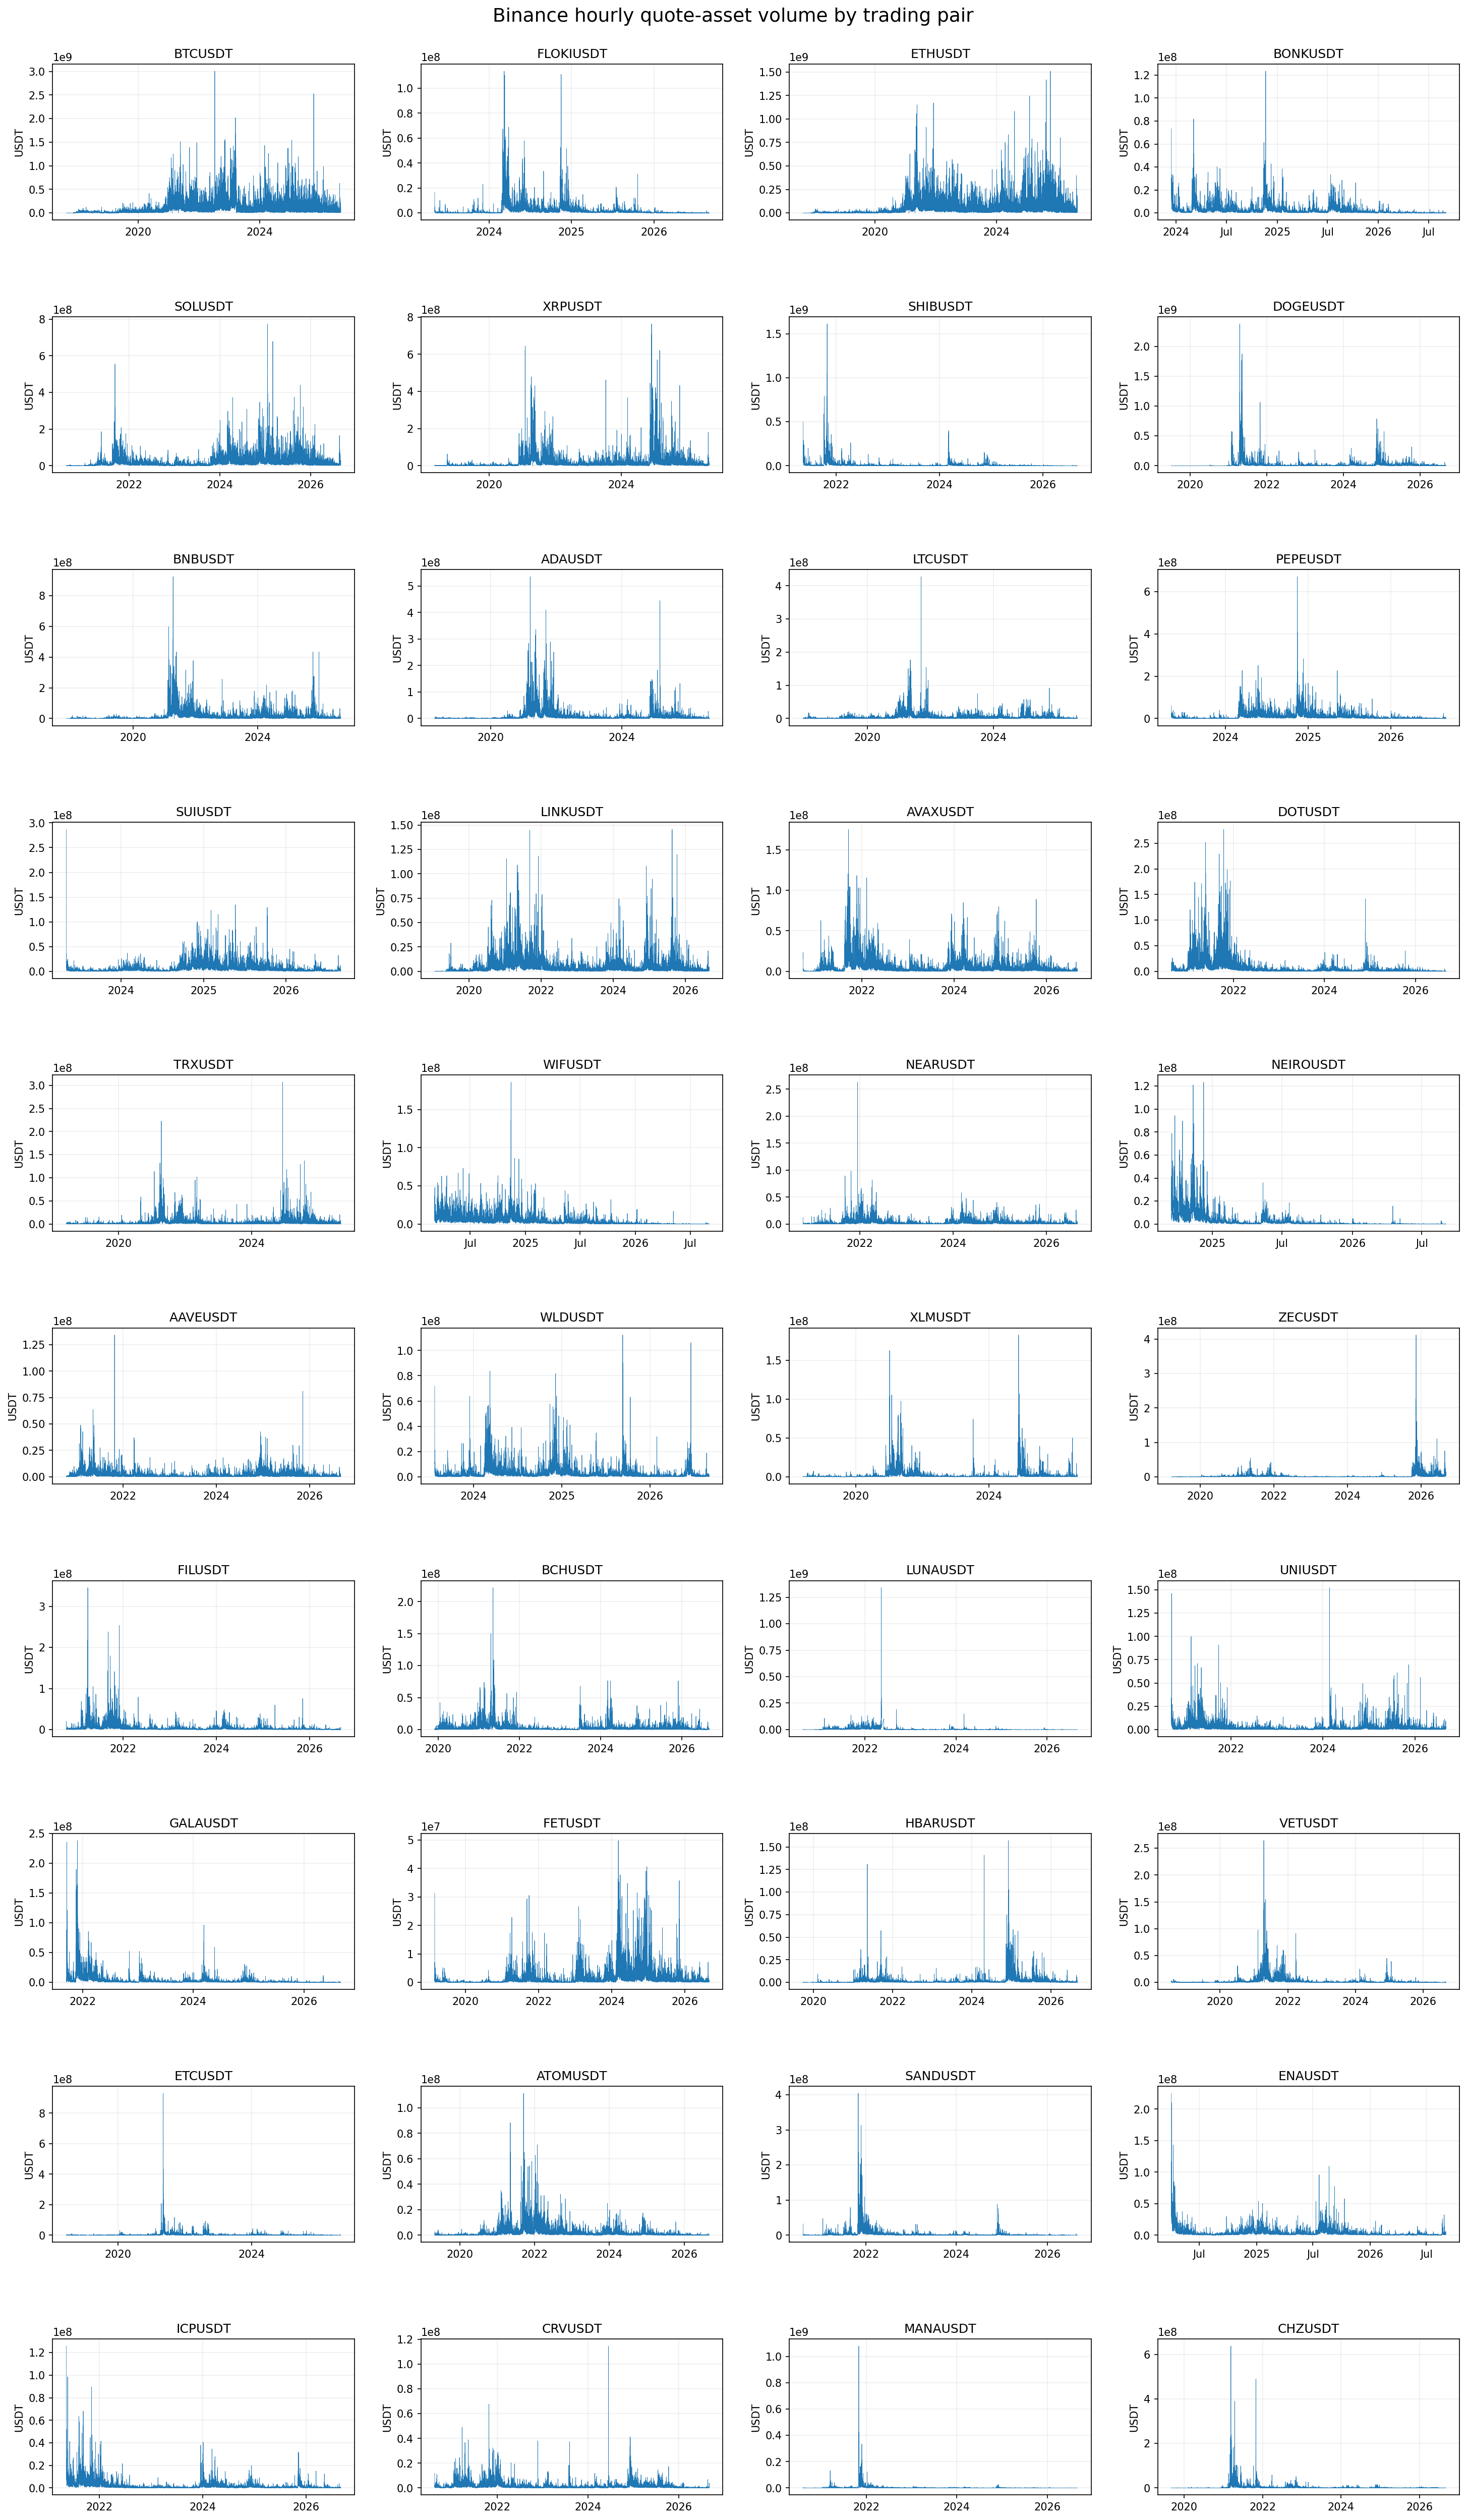

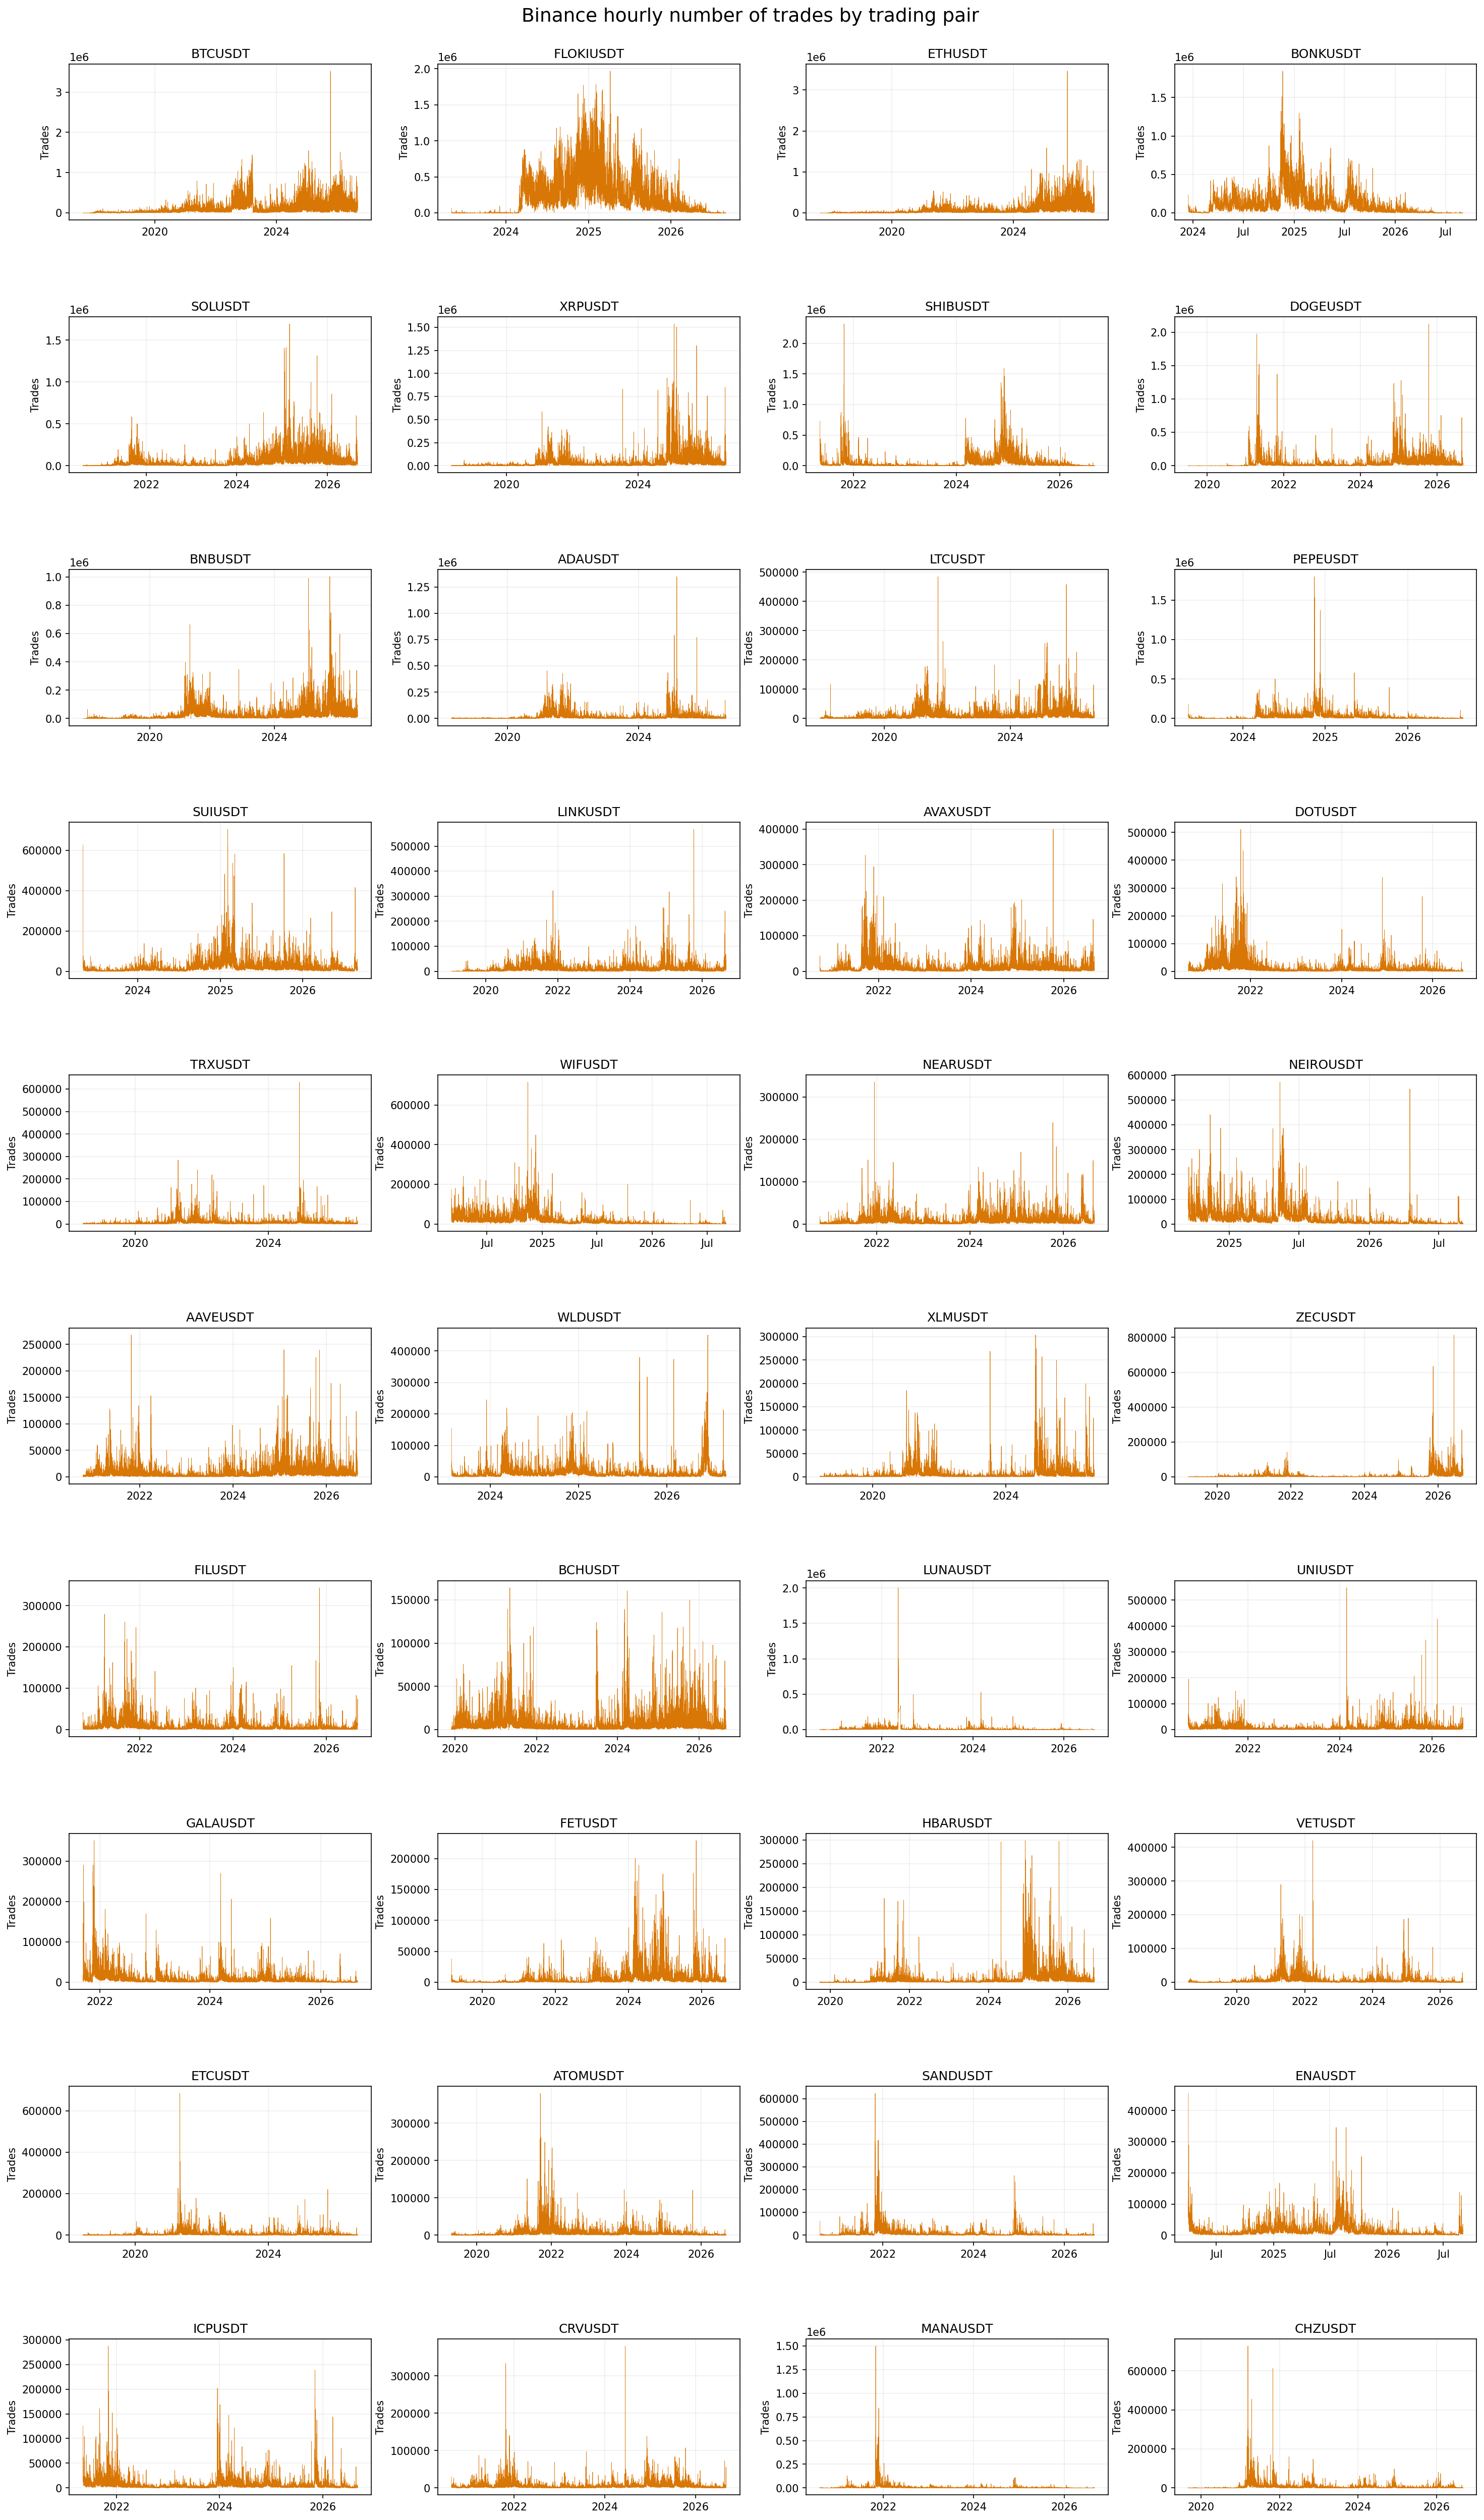

In [6]:
display(Image(filename=str(artifacts.quote_volume_overview)))
display(Image(filename=str(artifacts.trade_count_overview)))

## Interpretation limits

These are kline-level aggregates, not transaction-level records. Base-asset volume cannot be added across different cryptocurrencies because the units differ. Full-sample totals also reflect unequal listing dates and coverage spans. Strong positive skewness and excess kurtosis indicate that a small number of exceptionally active hours can dominate means, standard deviations, and totals; medians and interquartile ranges should be reported alongside them.